In [ ]:
!pip install borsapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.4/102.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 334.3/334.3 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.4/176.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 59.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 MB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 59.4 MB/s eta 0:00:00


In [ ]:
!pip install pandas

In [ ]:
!pip install numpy


In [ ]:
import pandas as pd
import borsapy

# --- Aşama 2: BİST 100 Havuzu (Canlı Ortam) ---
xu100 = borsapy.Index("XU100")
bist_sembolleri = xu100.component_symbols

print(f"Hedef Havuz Genişletildi: Toplam {len(bist_sembolleri)} tahta taranıyor...\n")
print("Sıfır Güven (Zero Trust) Tarayıcı Motoru Başlatıldı...\nBİST sunucuları taranıyor, lütfen bekleyin...\n")

hedef_tahtalar = []

for sembol in bist_sembolleri:
    try:
        # DOĞRU METOD: borsapy Ticker objesi ile 1 yıllık geçmiş veriyi çekmek
        hisse = borsapy.Ticker(sembol)
        df = hisse.history(period="1y")

        # Veri seti boşsa veya 200 günlük data oluşmamışsa tahtayı atla
        if df is None or df.empty or len(df) < 200:
            continue

        # OHLCV kuralı gereği kapanış sütunu 'Close' olarak gelir
        kapanis_sutunu = 'Close'

        # SMA Hesaplama (Pandas Rolling Window)
        df['SMA_50'] = df[kapanis_sutunu].rolling(window=50).mean()
        df['SMA_200'] = df[kapanis_sutunu].rolling(window=200).mean()

        # En güncel satırı al
        son_veri = df.iloc[-1]

        anlik_fiyat = son_veri[kapanis_sutunu]
        sma50 = son_veri['SMA_50']
        sma200 = son_veri['SMA_200']

        # Hatalı/Eksik veri (NaN) kontrolü
        if pd.isna(sma50) or pd.isna(sma200):
            continue

        # --- KATMAN 1: SIFIR GÜVEN (ZERO TRUST) FİLTRELERİ ---

        # Filtre 1: Ölüm Kesişimi Kalkanı
        filtre_1 = sma50 > sma200

        # Filtre 2: Ana Trend Onayı (Düşen bıçak engeli)
        filtre_2 = anlik_fiyat >= sma50

        # Filtre 3: Aktif Pusu Marjı (Fiyatın SMA_50'ye olan uzaklığı maksimum %3 olmalı)
        uzaklik_orani = (anlik_fiyat - sma50) / sma50
        filtre_3 = uzaklik_orani <= 0.03

        # Tüm güvenlik protokolleri onay verirse listeye ekle
        if filtre_1 and filtre_2 and filtre_3:
            hedef_tahtalar.append({
                'Sembol': sembol,
                'Fiyat (TL)': round(anlik_fiyat, 2),
                '50 SMA (TL)': round(sma50, 2),
                '200 SMA (TL)': round(sma200, 2),
                'Mesafe (%)': round(uzaklik_orani * 100, 2)
            })

    except Exception as e:
        # Hatalı sembolleri veya bağlantı kopmalarını sessizce geç
        continue

# --- SİSTEM ÇIKTISI (RAPORLAMA) ---
print("-" * 55)
print("TARAMA SONUCU: KUSURSUZ PUSU NOKTASINDAKİ HİSSELER")
print("-" * 55)

if len(hedef_tahtalar) > 0:
    sonuc_df = pd.DataFrame(hedef_tahtalar)
    print(sonuc_df.to_string(index=False))
else:
    print("Sistem Çıktısı: 0 Eşleşme.")
    print("Mevcut piyasa koşullarında Katman 1 pusu şartlarını sağlayan güvenli varlık bulunamadı (Tetiği Çekme).")

Hedef Havuz Genişletildi: Toplam 100 tahta taranıyor...

Sıfır Güven (Zero Trust) Tarayıcı Motoru Başlatıldı...
BİST sunucuları taranıyor, lütfen bekleyin...

-------------------------------------------------------
TARAMA SONUCU: KUSURSUZ PUSU NOKTASINDAKİ HİSSELER
-------------------------------------------------------
Sembol  Fiyat (TL)  50 SMA (TL)  200 SMA (TL)  Mesafe (%)
 ALARK      108.70       106.55        101.70        2.02
 ASELS      378.75       374.54        340.35        1.13
 BRSAN      645.50       629.88        587.00        2.48
 IEYHO      186.30       184.83        115.27        0.80
 KRDMD       43.74        43.11         35.59        1.47


In [ ]:
print(borsapy.Ticker("KRDMD").news)

                   Date                                             Title  \
0   03.09.2026 10:25:35                Pay Bazında Devre Kesici Bildirimi   
1   03.09.2026 10:00:06                Pay Bazında Devre Kesici Bildirimi   
2   02.09.2026 18:39:15  BISTECH Pay Piyasası Alım Satım Sistemi Duyurusu   
3   02.09.2026 10:49:34                Pay Bazında Devre Kesici Bildirimi   
4   02.09.2026 10:12:14                Pay Bazında Devre Kesici Bildirimi   
5   01.09.2026 15:31:18                Pay Bazında Devre Kesici Bildirimi   
6   01.09.2026 14:02:20                Pay Bazında Devre Kesici Bildirimi   
7   01.09.2026 13:42:06                Pay Bazında Devre Kesici Bildirimi   
8   01.09.2026 13:14:30                Pay Bazında Devre Kesici Bildirimi   
9   26.08.2026 18:16:49                          Pay Alım Satım Bildirimi   
10  24.08.2026 16:48:36         Borsada İşlem Gören Tipe Dönüşüm Duyurusu   
11  20.08.2026 12:18:12                Pay Bazında Devre Kesici Bildirimi   

In [ ]:
import pandas as pd
import borsapy as bp

print("Sıfır Güven (Zero Trust) Motoru v2.0 Başlatılıyor...")

# BİST 100 Sembollerini Çek (V2 KOD BU DAHA HIZLI)
xu100 = bp.Index("XU100")
bist_sembolleri = xu100.component_symbols

print(f"Toplam {len(bist_sembolleri)} tahtanın 1 yıllık geçmiş verisi BLOK halinde çekiliyor...")
print("Lütfen bekleyin (İşlem süresi v1'e göre ciddi oranda optimize edilmiştir)...\n")

hedef_tahtalar = []

try:
    # Toplu indirme (Batch Download) komutu: Sunucuyu yormadan tek seferde 100 hisseyi indirir
    data = bp.download(bist_sembolleri, period="1y", group_by="ticker")

    for sembol in bist_sembolleri:
        try:
            # Sadece ilgili hissenin verisini kopyala
            df = data[sembol].copy()

            # Sütun adı kontrolü (borsapy'nin dönüş formatına göre)
            kapanis_col = 'Close' if 'Close' in df.columns else 'Kapanış'

            # Eksik verileri temizle
            df = df.dropna(subset=[kapanis_col])

            # Yeni halka arzları (200 günden az verisi olanları) atla
            if len(df) < 200:
                continue

            # Algoritmik Hesaplamalar
            df['SMA_50'] = df[kapanis_col].rolling(window=50).mean()
            df['SMA_200'] = df[kapanis_col].rolling(window=200).mean()

            son_veri = df.iloc[-1]
            anlik_fiyat = son_veri[kapanis_col]
            sma50 = son_veri['SMA_50']
            sma200 = son_veri['SMA_200']

            if pd.isna(sma50) or pd.isna(sma200):
                continue

            # --- KATMAN 1: GÜVENLİK FİLTRELERİ ---
            filtre_1 = sma50 > sma200
            filtre_2 = anlik_fiyat >= sma50
            uzaklik_orani = (anlik_fiyat - sma50) / sma50
            filtre_3 = uzaklik_orani <= 0.03

            if filtre_1 and filtre_2 and filtre_3:
                hedef_tahtalar.append({
                    'Sembol': sembol,
                    'Fiyat (TL)': round(anlik_fiyat, 2),
                    '50 SMA (TL)': round(sma50, 2),
                    '200 SMA (TL)': round(sma200, 2),
                    'Mesafe (%)': round(uzaklik_orani * 100, 2)
                })
        except Exception:
            # Hatalı veri paketlerini sistemi durdurmamak için sessizce geç
            continue

except Exception as e:
    print(f"API Bağlantı Hatası: {e}")

# --- SİSTEM ÇIKTISI (RAPORLAMA) ---
print("-" * 55)
print("TARAMA SONUCU (v2.0): KUSURSUZ PUSU NOKTASINDAKİ HİSSELER")
print("-" * 55)

if len(hedef_tahtalar) > 0:
    sonuc_df = pd.DataFrame(hedef_tahtalar)
    print(sonuc_df.to_string(index=False))
    print("-" * 55)
    print("Operasyonel Komut: Listeden bir hisse seç ve 1S (Saatlik) + 1G (Günlük) grafiklerini radara yükle.")
else:
    print("Sistem Çıktısı: 0 Eşleşme.")
    print("Sıfır Güven Kalkanı devrede: Piyasada şu an şartlarımızı sağlayan risksiz bir tahta yok.")

Sıfır Güven (Zero Trust) Motoru v2.0 Başlatılıyor...
Toplam 100 tahtanın 1 yıllık geçmiş verisi BLOK halinde çekiliyor...
Lütfen bekleyin (İşlem süresi v1'e göre ciddi oranda optimize edilmiştir)...

-------------------------------------------------------
TARAMA SONUCU (v2.0): KUSURSUZ PUSU NOKTASINDAKİ HİSSELER
-------------------------------------------------------
Sembol  Fiyat (TL)  50 SMA (TL)  200 SMA (TL)  Mesafe (%)
 ALARK      108.70       106.55        101.70        2.02
 ASELS      378.50       374.53        340.35        1.06
 BRSAN      644.50       629.86        587.00        2.32
  EFOR       19.30        18.74         18.08        2.96
 IEYHO      186.30       184.83        115.27        0.80
 KRDMD       43.74        43.11         35.59        1.47
-------------------------------------------------------
Operasyonel Komut: Listeden bir hisse seç ve 1S (Saatlik) + 1G (Günlük) grafiklerini radara yükle.


In [ ]:
import pandas as pd
import borsapy as bp
import logging
import sys

# --- KONFİGÜRASYON VE SABİTLER (Clean Code Prensibi) ---
SMA_KISA = 50
SMA_UZUN = 200
MAKS_UZAKLIK = 0.03
MIN_VERI_GUNU = 200

# Profesyonel Loglama Altyapısı
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

logging.info("Sıfır Güven Motoru v3.0 [Kurşun Geçirmez Sürüm] Başlatılıyor...")

try:
    xu100 = bp.Index("XU100")
    bist_sembolleri = xu100.component_symbols
    if not bist_sembolleri:
        raise ValueError("Endeks bileşenleri boş döndü.")
except Exception as e:
    logging.critical(f"Kritik API Hatası (Endeks): {e}")
    sys.exit(1) # Sistem güvenli bir şekilde kapatılır

logging.info(f"Toplam {len(bist_sembolleri)} tahta için blok veri çekimi (Batch Download) devrede...")

hedef_tahtalar = []

try:
    data = bp.download(bist_sembolleri, period="1y", group_by="ticker")

    for sembol in bist_sembolleri:
        try:
            # 1. Veri Yapısı Doğrulaması (KeyError Koruması)
            if sembol not in data:
                logging.warning(f"[{sembol}] Veri paketinde bulunamadı, atlanıyor.")
                continue

            df = data[sembol].copy()

            # 2. Sütun Doğrulaması
            kapanis_col = 'Close' if 'Close' in df.columns else 'Kapanış'
            if kapanis_col not in df.columns:
                logging.debug(f"[{sembol}] Kapanış sütunu bulunamadı.")
                continue

            # 3. Tip Güvenliği (Type Safety) ve Temizlik
            df[kapanis_col] = pd.to_numeric(df[kapanis_col], errors='coerce')
            df = df.dropna(subset=[kapanis_col])

            # 4. Zaman Serisi Bütünlüğü (Kronolojik Sıralama Garantisi)
            df = df.sort_index(ascending=True)

            # 5. Veri Yeterliliği
            if len(df) < MIN_VERI_GUNU:
                continue

            # Algoritmik Hesaplamalar
            df['SMA_50'] = df[kapanis_col].rolling(window=SMA_KISA).mean()
            df['SMA_200'] = df[kapanis_col].rolling(window=SMA_UZUN).mean()

            son_veri = df.iloc[-1]
            anlik_fiyat = float(son_veri[kapanis_col])
            sma50 = float(son_veri['SMA_50'])
            sma200 = float(son_veri['SMA_200'])

            # 6. Sıfıra Bölünme (ZeroDivision) ve NaN Koruması
            if pd.isna(sma50) or pd.isna(sma200) or sma50 == 0:
                continue

            # --- KATMAN 1: GÜVENLİK FİLTRELERİ ---
            filtre_1 = sma50 > sma200
            filtre_2 = anlik_fiyat >= sma50
            uzaklik_orani = (anlik_fiyat - sma50) / sma50
            filtre_3 = uzaklik_orani <= MAKS_UZAKLIK

            if filtre_1 and filtre_2 and filtre_3:
                hedef_tahtalar.append({
                    'Sembol': sembol,
                    'Fiyat (TL)': round(anlik_fiyat, 2),
                    '50 SMA (TL)': round(sma50, 2),
                    '200 SMA (TL)': round(sma200, 2),
                    'Mesafe (%)': round(uzaklik_orani * 100, 2)
                })
        except Exception as e:
            # Sessiz hata yutmak yerine arka planda logla
            logging.debug(f"[{sembol}] İşlem hatası: {e}")
            continue

except Exception as e:
    logging.critical(f"Blok Veri İndirme Çöktü: {e}")
    sys.exit(1)

# --- SİSTEM ÇIKTISI (RAPORLAMA) ---
print("\n" + "=" * 60)
print("TARAMA SONUCU (v3.0 - BULLETPROOF): KUSURSUZ PUSU NOKTALARI")
print("=" * 60)

if hedef_tahtalar:
    sonuc_df = pd.DataFrame(hedef_tahtalar)
    print(sonuc_df.to_string(index=False))
    print("-" * 60)
    print("Operasyonel Komut: 1S (Saatlik) + 1G (Günlük) grafikleriyle Katman 2 doğrulamasını başlatın.")
else:
    print("Sistem Çıktısı: 0 Eşleşme.")
    print("Sıfır Güven Kalkanı: Mevcut piyasada algoritmik şartları sağlayan güvenli varlık bulunmamaktadır.")


TARAMA SONUCU (v3.0 - BULLETPROOF): KUSURSUZ PUSU NOKTALARI
Sembol  Fiyat (TL)  50 SMA (TL)  200 SMA (TL)  Mesafe (%)
 ALARK      108.60       106.55        101.70        1.92
 ASELS      378.25       374.52        340.35        0.99
 BRSAN      647.00       629.91        587.01        2.71
  EFOR       19.27        18.74         18.08        2.81
 IEYHO      186.30       184.83        115.27        0.80
 KRDMD       43.68        43.11         35.59        1.33
------------------------------------------------------------
Operasyonel Komut: 1S (Saatlik) + 1G (Günlük) grafikleriyle Katman 2 doğrulamasını başlatın.


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import logging
from typing import Tuple, Optional
import warnings

# Terminal kirliliğini ve yfinance uyarılarını bastır
warnings.filterwarnings('ignore')

# Profesyonel Loglama Altyapısı
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# --- SIFIR GÜVEN (ZERO TRUST) MATEMATİK MOTORU ---
def rsi_hesapla(fiyatlar: pd.Series, periyot: int = 14) -> pd.Series:
    """Matematiksel olarak sıfıra bölünme korumalı RSI hesaplayıcısı."""
    fark = fiyatlar.diff()
    kazanc = fark.where(fark > 0, 0.0)
    kayip = -fark.where(fark < 0, 0.0)

    avg_kazanc = kazanc.ewm(com=periyot-1, min_periods=periyot).mean()
    avg_kayip = kayip.ewm(com=periyot-1, min_periods=periyot).mean()

    # Sıfıra bölünme zırhı: Kayıp 0 ise RS sonsuzdur, RSI 100 olur.
    rs = avg_kazanc / avg_kayip.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi.fillna(100)

def macd_hesapla(fiyatlar: pd.Series, kisa: int = 12, uzun: int = 26, sinyal_periyot: int = 9) -> Tuple[pd.Series, pd.Series, pd.Series]:
    """Vektörel MACD operasyonu."""
    kisa_ema = fiyatlar.ewm(span=kisa, adjust=False).mean()
    uzun_ema = fiyatlar.ewm(span=uzun, adjust=False).mean()

    macd_cizgisi = kisa_ema - uzun_ema
    sinyal_cizgisi = macd_cizgisi.ewm(span=sinyal_periyot, adjust=False).mean()
    macd_histogram = macd_cizgisi - sinyal_cizgisi

    return macd_cizgisi, sinyal_cizgisi, macd_histogram

def veri_temizle(df: pd.DataFrame) -> pd.DataFrame:
    """yfinance veri yapısındaki anormallikleri ve eksikleri onarır."""
    if df.empty:
        return df
    # MultiIndex koruması (yfinance güncelleme hatalarına karşı)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)

    # Eksik verileri (NaN) bir önceki günün/saatin verisiyle doldur (Forward Fill)
    df = df.ffill().bfill()
    return df

# --- KATMAN 2 & 3 GÖRSELLEŞTİRME TERMİNALİ ---
def operasyon_ekrani_ciz(sembol: str) -> None:
    yf_sembol = f"{sembol}.IS"
    logging.info(f"[{sembol}] İstihbarat paketleri indiriliyor (1G ve 1S)...")

    try:
        # Otonom Veri Çekimi
        gunluk_veri = yf.download(yf_sembol, period="1y", interval="1d", progress=False)
        saatlik_veri = yf.download(yf_sembol, period="1mo", interval="1h", progress=False)

        gunluk_veri = veri_temizle(gunluk_veri)
        saatlik_veri = veri_temizle(saatlik_veri)

        if gunluk_veri.empty or saatlik_veri.empty:
            logging.error(f"[{sembol}] Ağ reddi: Yeterli hacim veya zaman serisi verisi bulunamadı.")
            return

        # Günlük Trend (Katman 2) Mimarisi
        gunluk_veri['SMA_50'] = gunluk_veri['Close'].rolling(window=50).mean()
        gunluk_veri['SMA_200'] = gunluk_veri['Close'].rolling(window=200).mean()

        # Saatlik Mikro Tetik (Katman 3) Mimarisi
        saatlik_veri['RSI'] = rsi_hesapla(saatlik_veri['Close'])
        macd, sinyal, hist = macd_hesapla(saatlik_veri['Close'])
        saatlik_veri['MACD'] = macd
        saatlik_veri['Sinyal'] = sinyal
        saatlik_veri['Hist'] = hist

        # --- PROFESYONEL ÇİZİM MOTORU (Dark Mode) ---
        plt.style.use('dark_background') # Göz yormayan, kontrastlı operasyon arayüzü
        fig = plt.figure(figsize=(18, 10))
        fig.suptitle(f"SİSTEM: {sembol} | SIFIR GÜVEN (ZERO TRUST) TERMİNALİ", fontsize=16, fontweight='bold', color='cyan')

        # 1. GÜNLÜK GRAFİK (Sol Blok)
        ax1 = plt.subplot2grid((3, 2), (0, 0), rowspan=2)
        ax1.plot(gunluk_veri.index, gunluk_veri['Close'], label='Kapanış (1G)', color='white', linewidth=1.5)
        ax1.plot(gunluk_veri.index, gunluk_veri['SMA_50'], label='50 SMA (Tetik/Destek)', color='#00ff00', linewidth=2) # Neon Yeşil
        ax1.plot(gunluk_veri.index, gunluk_veri['SMA_200'], label='200 SMA (Ana Trend)', color='#ff0044', linewidth=2) # Neon Kırmızı
        ax1.set_title("KATMAN 2: Makro Trend ve Mesafe Analizi", color='gray')
        ax1.grid(True, alpha=0.2, linestyle='--')
        ax1.legend(loc='upper left', framealpha=0.3)

        # 2. SAATLİK FİYAT (Sağ Üst Blok)
        ax2 = plt.subplot2grid((3, 2), (0, 1), rowspan=1)
        ax2.plot(saatlik_veri.index, saatlik_veri['Close'], label='Kapanış (1S)', color='white', linewidth=1.2)
        ax2.set_title("KATMAN 3: Saatlik Pusu (Son 1 Ay)", color='gray')
        ax2.grid(True, alpha=0.2, linestyle='--')
        ax2.legend(loc='upper left', framealpha=0.3)

        # 3. SAATLİK MACD (Sağ Orta Blok)
        ax3 = plt.subplot2grid((3, 2), (1, 1), sharex=ax2)
        ax3.plot(saatlik_veri.index, saatlik_veri['MACD'], label='MACD', color='#00ccff', linewidth=1.2)
        ax3.plot(saatlik_veri.index, saatlik_veri['Sinyal'], label='Sinyal', color='#ffaa00', linewidth=1.2)
        ax3.bar(saatlik_veri.index, saatlik_veri['Hist'], color=np.where(saatlik_veri['Hist']>0, '#00ff00', '#ff0044'), alpha=0.6)
        ax3.set_title("Saatlik MACD (Momentum)", color='gray')
        ax3.grid(True, alpha=0.2, linestyle='--')
        ax3.legend(loc='upper left', framealpha=0.3)

        # 4. SAATLİK RSI (Sağ Alt Blok)
        ax4 = plt.subplot2grid((3, 2), (2, 1), sharex=ax2)
        ax4.plot(saatlik_veri.index, saatlik_veri['RSI'], color='#cc00ff', label='RSI (14)', linewidth=1.5)
        ax4.axhline(70, color='#ff0044', linestyle='--', alpha=0.7, label='Aşırı Alım')
        ax4.axhline(30, color='#00ff00', linestyle='--', alpha=0.7, label='Aşırı Satım (Pusu)')
        ax4.fill_between(saatlik_veri.index, saatlik_veri['RSI'], 30, where=(saatlik_veri['RSI'] <= 30), color='#00ff00', alpha=0.3)
        ax4.set_title("Saatlik RSI Gücü", color='gray')
        ax4.grid(True, alpha=0.2, linestyle='--')
        ax4.legend(loc='upper left', framealpha=0.3)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        logging.info(f"[{sembol}] Görselleştirme terminali başarıyla oluşturuldu.")
        plt.show()

    except Exception as e:
        logging.critical(f"[{sembol}] İşlem Çekirdeği Çöktü: {e}")

# KULLANIM KOMUTU:
# operasyon_ekrani_ciz('ASELS')

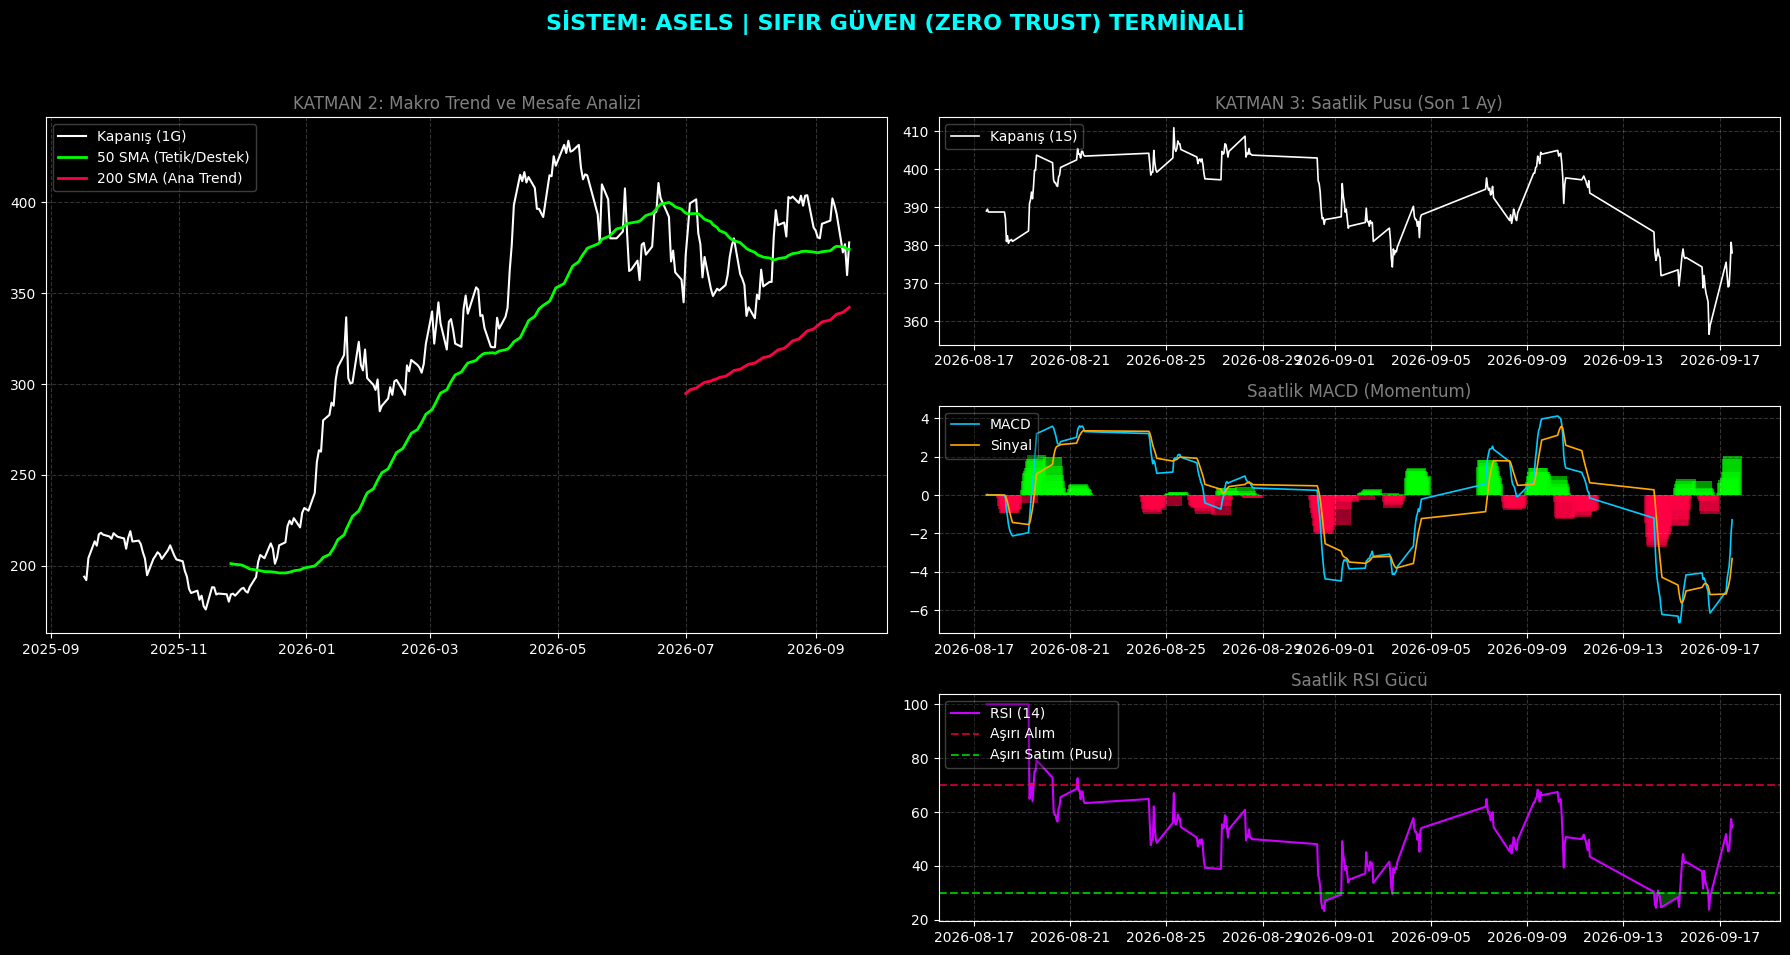

In [ ]:
operasyon_ekrani_ciz('ASELS')

ALTTAKİ HEM OTONOM OLARAK BORSAYI İSTEĞİME GÖRE TARIYOR HEM DE GRAFİĞE DÖKÜYOR ANALİZ İÇİN


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import borsapy as bp
import logging
import sys
import time
import warnings
from typing import Tuple

# --- KONFİGÜRASYON VE SABİTLER ---
SMA_KISA = 50
SMA_UZUN = 200
MAKS_UZAKLIK = 0.03
MIN_VERI_GUNU = 200
API_BEKLEME_SURESI = 2.0  # Ban yememek için 2 saniyelik hız kesici

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

# =====================================================================
# MODÜL 1: SIFIR GÜVEN (ZERO TRUST) MATEMATİK VE ÇİZİM MOTORU
# =====================================================================
def rsi_hesapla(fiyatlar: pd.Series, periyot: int = 14) -> pd.Series:
    fark = fiyatlar.diff()
    kazanc = fark.where(fark > 0, 0.0)
    kayip = -fark.where(fark < 0, 0.0)
    avg_kazanc = kazanc.ewm(com=periyot-1, min_periods=periyot).mean()
    avg_kayip = kayip.ewm(com=periyot-1, min_periods=periyot).mean()
    rs = avg_kazanc / avg_kayip.replace(0, np.nan)
    return (100 - (100 / (1 + rs))).fillna(100)

def macd_hesapla(fiyatlar: pd.Series, kisa: int = 12, uzun: int = 26, sinyal_periyot: int = 9) -> Tuple[pd.Series, pd.Series, pd.Series]:
    kisa_ema = fiyatlar.ewm(span=kisa, adjust=False).mean()
    uzun_ema = fiyatlar.ewm(span=uzun, adjust=False).mean()
    macd_cizgisi = kisa_ema - uzun_ema
    sinyal_cizgisi = macd_cizgisi.ewm(span=sinyal_periyot, adjust=False).mean()
    macd_histogram = macd_cizgisi - sinyal_cizgisi
    return macd_cizgisi, sinyal_cizgisi, macd_histogram

def veri_temizle(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty: return df
    if isinstance(df.columns, pd.MultiIndex): df.columns = df.columns.droplevel(1)
    return df.ffill().bfill()

def operasyon_ekrani_ciz(sembol: str, gunluk_veri: pd.DataFrame) -> None:
    """
    OPTİMİZASYON: Günlük veri API'den tekrar çekilmez, tarayıcıdan RAM üzerinden alınır.
    Sadece Saatlik mikro-istihbarat için API çağrısı yapılır.
    """
    yf_sembol = f"{sembol}.IS"
    logging.info(f"[{sembol}] Saatlik istihbarat paketi indiriliyor (1S)...")

    try:
        # API Ban Koruması: İnsan taklidi gecikme
        time.sleep(API_BEKLEME_SURESI)

        saatlik_veri = yf.download(yf_sembol, period="1mo", interval="1h", progress=False)
        saatlik_veri = veri_temizle(saatlik_veri)

        if saatlik_veri.empty:
            logging.error(f"[{sembol}] Saatlik veri reddi: Ağ yanıt vermedi.")
            return

        # Saatlik Mikro Tetik (Katman 3) Mimarisi
        saatlik_veri['RSI'] = rsi_hesapla(saatlik_veri['Close'])
        macd, sinyal, hist = macd_hesapla(saatlik_veri['Close'])
        saatlik_veri['MACD'] = macd
        saatlik_veri['Sinyal'] = sinyal
        saatlik_veri['Hist'] = hist

        # --- PROFESYONEL ÇİZİM MOTORU ---
        plt.style.use('dark_background')
        fig = plt.figure(figsize=(18, 10))
        fig.suptitle(f"SİSTEM: {sembol} | SIFIR GÜVEN (ZERO TRUST) TERMİNALİ", fontsize=16, fontweight='bold', color='cyan')

        ax1 = plt.subplot2grid((3, 2), (0, 0), rowspan=2)
        ax1.plot(gunluk_veri.index, gunluk_veri['Close'], label='Kapanış (1G)', color='white', linewidth=1.5)
        ax1.plot(gunluk_veri.index, gunluk_veri['SMA_50'], label='50 SMA (Tetik/Destek)', color='#00ff00', linewidth=2)
        ax1.plot(gunluk_veri.index, gunluk_veri['SMA_200'], label='200 SMA (Ana Trend)', color='#ff0044', linewidth=2)
        ax1.set_title("KATMAN 2: Makro Trend ve Mesafe Analizi (RAM Cache)", color='gray')
        ax1.grid(True, alpha=0.2, linestyle='--')
        ax1.legend(loc='upper left', framealpha=0.3)

        ax2 = plt.subplot2grid((3, 2), (0, 1), rowspan=1)
        ax2.plot(saatlik_veri.index, saatlik_veri['Close'], label='Kapanış (1S)', color='white', linewidth=1.2)
        ax2.set_title("KATMAN 3: Saatlik Pusu (Son 1 Ay)", color='gray')
        ax2.grid(True, alpha=0.2, linestyle='--')
        ax2.legend(loc='upper left', framealpha=0.3)

        ax3 = plt.subplot2grid((3, 2), (1, 1), sharex=ax2)
        ax3.plot(saatlik_veri.index, saatlik_veri['MACD'], label='MACD', color='#00ccff', linewidth=1.2)
        ax3.plot(saatlik_veri.index, saatlik_veri['Sinyal'], label='Sinyal', color='#ffaa00', linewidth=1.2)
        ax3.bar(saatlik_veri.index, saatlik_veri['Hist'], color=np.where(saatlik_veri['Hist']>0, '#00ff00', '#ff0044'), alpha=0.6)
        ax3.set_title("Saatlik MACD (Momentum)", color='gray')
        ax3.grid(True, alpha=0.2, linestyle='--')
        ax3.legend(loc='upper left', framealpha=0.3)

        ax4 = plt.subplot2grid((3, 2), (2, 1), sharex=ax2)
        ax4.plot(saatlik_veri.index, saatlik_veri['RSI'], color='#cc00ff', label='RSI (14)', linewidth=1.5)
        ax4.axhline(70, color='#ff0044', linestyle='--', alpha=0.7)
        ax4.axhline(30, color='#00ff00', linestyle='--', alpha=0.7)
        ax4.fill_between(saatlik_veri.index, saatlik_veri['RSI'], 30, where=(saatlik_veri['RSI'] <= 30), color='#00ff00', alpha=0.3)
        ax4.set_title("Saatlik RSI Gücü", color='gray')
        ax4.grid(True, alpha=0.2, linestyle='--')
        ax4.legend(loc='upper left', framealpha=0.3)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

        # OOM (Out of Memory) KORUMASI: Çizilen grafiği RAM'den kalıcı olarak sil
        plt.close(fig)

    except Exception as e:
        logging.critical(f"[{sembol}] Çizim Çekirdeği Çöktü: {e}")


# =====================================================================
# MODÜL 2: OTONOM TARAMA VE TETİKLEYİCİ BEYİN (V6.0)
# =====================================================================
logging.info("Sıfır Güven Motoru v6.0 [The Juggernaut] Başlatılıyor...")

try:
    xu100 = bp.Index("XU100")
    bist_sembolleri = xu100.component_symbols
    if not bist_sembolleri:
        raise ValueError("Endeks bileşenleri boş döndü.")
except Exception as e:
    logging.critical(f"Kritik API Hatası (Endeks): {e}")
    sys.exit(1)

logging.info(f"Toplam {len(bist_sembolleri)} tahta taranıyor (Blok Veri/Batch Download)...")
hedef_tahtalar = []

try:
    data = bp.download(bist_sembolleri, period="1y", group_by="ticker")
    for sembol in bist_sembolleri:
        try:
            if sembol not in data: continue
            df = data[sembol].copy()

            kapanis_col = 'Close' if 'Close' in df.columns else 'Kapanış'
            if kapanis_col not in df.columns: continue

            df[kapanis_col] = pd.to_numeric(df[kapanis_col], errors='coerce')
            df = df.dropna(subset=[kapanis_col]).sort_index(ascending=True)

            if len(df) < MIN_VERI_GUNU: continue

            df['SMA_50'] = df[kapanis_col].rolling(window=SMA_KISA).mean()
            df['SMA_200'] = df[kapanis_col].rolling(window=SMA_UZUN).mean()

            son_veri = df.iloc[-1]
            anlik_fiyat = float(son_veri[kapanis_col])
            sma50 = float(son_veri['SMA_50'])
            sma200 = float(son_veri['SMA_200'])

            if pd.isna(sma50) or pd.isna(sma200) or sma50 == 0: continue

            filtre_1 = sma50 > sma200
            filtre_2 = anlik_fiyat >= sma50
            uzaklik_orani = (anlik_fiyat - sma50) / sma50
            filtre_3 = uzaklik_orani <= MAKS_UZAKLIK

            if filtre_1 and filtre_2 and filtre_3:
                # OPTİMİZASYON: Günlük DF'i yeniden hesaplamamak için sözlüğe paketliyoruz
                hedef_tahtalar.append({
                    'Sembol': sembol,
                    'Fiyat (TL)': round(anlik_fiyat, 2),
                    '50 SMA': round(sma50, 2),
                    'Mesafe (%)': round(uzaklik_orani * 100, 2),
                    'DF': df
                })
        except Exception:
            continue

except Exception as e:
    logging.critical(f"Blok Veri İndirme Çöktü: {e}")
    sys.exit(1)

# =====================================================================
# ÇIKTI VE OTONOM GÖRSELLEŞTİRME TETİĞİ
# =====================================================================
print("\n" + "=" * 65)
print("TARAMA SONUCU (v6.0 - THE JUGGERNAUT)")
print("=" * 65)

if hedef_tahtalar:
    # Konsola basarken 'DF' objesini gizlemek için geçici bir kopya oluşturuyoruz
    rapor_listesi = [{k: v for k, v in d.items() if k != 'DF'} for d in hedef_tahtalar]
    sonuc_df = pd.DataFrame(rapor_listesi)
    print(sonuc_df.to_string(index=False))
    print("-" * 65)
    print(f"Otonom Çizim Motoru Devrede... Hedef grafikler API limitleri korunarak sırayla basılıyor.\n")

    # API Ban korumalı ve Bellek sızıntısı giderilmiş otonom çizim döngüsü
    for hedef in hedef_tahtalar:
        operasyon_ekrani_ciz(hedef['Sembol'], hedef['DF'])

else:
    print("Sistem Çıktısı: 0 Eşleşme.")
    print("Sıfır Güven Kalkanı: Piyasada kurallarımıza uyan güvenli varlık bulunamadı. Nakitte bekle.")

ModuleNotFoundError: No module named 'borsapy'